# **1. ASR(Automatic Speech Recognition)**
- 자동 음성인식. 사람이 말하는 소리를 컴퓨터가 글자로 바꾸는 기술
- Qwen3-ASR: ASR을 수행하는 AI 모델
- Whisper: OpenAI가 개발한 ASR 모델
- STT: Speech-to-Text의 약자로, 음성을 문자로 변환하는 기능

In [2]:
# 소리를 측정: 소리 신호가 얼마나 위쪽 또는 아래쪽으로 흔들리는지 숫자로 표현
import numpy as np

# 마이너스는 나쁜 소리가 아니라 파형의 반대 방향을 나타냄
data = np.array([0.0, 0.4, 0.8, 0.4, 0.0, -0.4, -0.8, -0.4], dtype=np.float32)
print("측정값:", data)
print("측정 횟수:", len(data))
print("가장 큰 절댓값:", np.max(np.abs(data)))

측정값: [ 0.   0.4  0.8  0.4  0.  -0.4 -0.8 -0.4]
측정 횟수: 8
가장 큰 절댓값: 0.8


### Hz(헤르츠)
- 1초에 몇 번 반복되는가를 나타내는 단위
- 샘플링 레이트(sample rate)를 말할 때 1초에 신호를 몇번 측정하는가를 뜻함
    - 1 KHz = 1000 Hz
    - 16 KHz = 16000 Hz

> 소리의 주파수(음높이 관련) Hz와 샘플링 레이트 Hz는 서로 다른 개념. 주파수는 소리가 1초에 얼마나 진동하는지, 샘플링 레이트는 컴퓨터가 1초에 몇 번 측정하는지를 말함

In [4]:
sample_rate = 16000
seconds = 4
num_samples = sample_rate* seconds
print(f"{seconds}초 동안 만들어지는 측정값: {num_samples:,}개")

4초 동안 만들어지는 측정값: 64,000개


In [10]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'

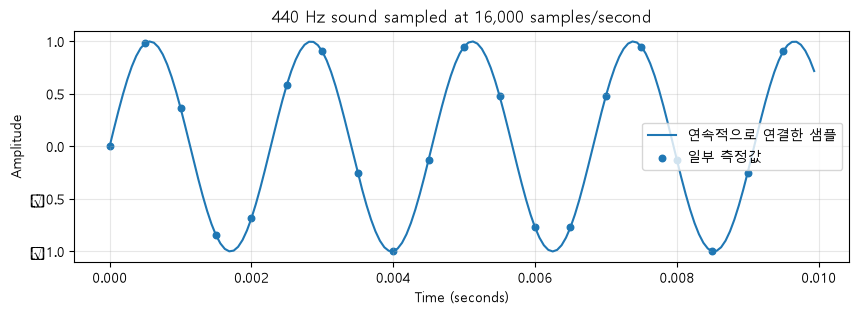

In [11]:
import numpy as np

sample_rate = 16000
duration = 0.01
t = np.arange(int(sample_rate * duration)) / sample_rate
frequency = 440
wave = np.sin(2 * np.pi * frequency * t)
plt.figure(figsize=(10, 3))
plt.plot(t, wave, label='연속적으로 연결한 샘플')
plt.scatter(t[::8], wave[::8], s=22, label='일부 측정값')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('440 Hz sound sampled at 16,000 samples/second')
plt.legend()
plt.grid(alpha=.3)
plt.show()

### WAV
- 디지털 소리를 담는 파일 형식. 압축되지 않은 PCM 데이터를 저장할 수 있음
- 모노(Mono): 소리 채널이 하나. channels=1
- 스테레오(Stereo): 소리 채널이 두 개. channels=2
- float32로 소리 측정값을 저장. 

> 16kHz 모노 4초: (64000, ) 모양의 1차원 배열. 녹음 라이브러리는 (64000, 1)처럼 채널 축을 포함해 사용

In [12]:
# soundfile: 음성 파일을 읽거나 저장할 때 사용하는 모듈
# 예) wav같은 소리 파일을 숫자 데이터로 가져오거나, 숫자 데이터를 다시 소리 파일로 저장하는 도구
import soundfile as sf

sr = 16000  # 1초에 소리를 16000번 측정
t = np.arange(sr) / sr
# 0.2: 진폭. 만들어지는 소리 신호의 크기를 조절하는 값
# 440: 소리의 주파수. 1초에 소리가 440번 진동
tone = (0.2 * np.sin(2 * np.pi * 440 * t)).astype(np.float32)
sf.write("practice_440hz.wav", tone, sr)
loaded, loaded_sr = sf.read("practice_440hz.wav")
print("저장된 샘플링 레이트:", loaded_sr)
print("샘플 개수:", len(loaded))
print("녹음 길이:", len(loaded) / loaded_sr, "초")

저장된 샘플링 레이트: 16000
샘플 개수: 16000
녹음 길이: 1.0 초


### Qwen3-ASR
- Qwen 팀이 공개한 자동 음성인식 모델
- Qwen3-ASR-1.7B
    - Qwen3-ASR: 음성인식 목적 모델
    - 1.7B: 약 17억 개의 매개변수(B = Billion = 10억)

pip install qwen-asr

In [14]:
from qwen_asr import Qwen3ASRModel

ModuleNotFoundError: No module named 'qwen_asr'

In [ ]:
model_name = "Qwen/Qwen3-ASR-1.7B"

model = Qwen3ASRModel.from_pretrained(
    model_name, max_inference_batch_size=1, max_new_tokens=256
)

NameError: name 'model_name' is not defined